# 08. Terceira base intocada: SpamAssassin (decisão D10, pré-registrada)

**Pergunta:** o Stacking 8 (o Stacking 7 + o TabPFN, modelo de fundação para tabelas) deve virar o filtro
**Generalista**, aquele indicado para caixas de e-mail novas?

Na base externa (Enron2-6), o Stacking 8 custou menos. Mas esse achado veio de *olhar* a base externa; usá-lo
para escolher faria dela uma base de seleção. Por isso a regra foi **escrita antes** (D10 no registro de
decisões) e é aplicada aqui numa base que nenhuma escolha usou:

> O Stacking 8 padrão substitui o Stacking 7 padrão se reduzir o custo por mil e-mails (limiar de custo, λ = 9)
> com P(redução) ≥ 0,90 no bootstrap por grupo, sem piorar o MCC no limiar de custo em mais de 0,01.

**A base.** SpamAssassin public corpus (2002-2003): 6047 mensagens brutas, de outras pessoas e outra época,
convertidas para o formato da AUEB por `spamfilter.conversao` (que reproduz 90,5% dos e-mails brutos da
caixa farmer-d exatamente) e contadas com o vocabulário do CSV. Treino: os 5172 e-mails do CSV, sem ajuste.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import caminhos, estatistica, externo, graficos, metricas, modelos, saidas
from spamfilter.dados import carregar
from spamfilter.motor import Motor

base = carregar()
Xsa, ysa, gsa, mantidas = externo.carregar_spamassassin(base)
print(f"SpamAssassin: {len(ysa)} mensagens ({(ysa == 0).sum()} e-mails reais, {(ysa == 1).sum()} spams; "
      f"{(~mantidas).sum()} cópia(s) do CSV removida(s))")

SpamAssassin: 6046 mensagens (4150 e-mails reais, 1896 spams; 1 cópia(s) do CSV removida(s))


## 1. Os 7 membros: reaproveita as notas out-of-fold da base externa e treina só o modelo final

In [2]:
m = Motor(base, cache=caminhos.RESULTADOS / "cache_motor", leitura_extra=[caminhos.CACHE_MOTOR], log=print)
m.adicionar_externo({})
P, E = modelos.STACKING7_PADRAO, modelos.STACKING7_ESPECIALISTA
pares = sorted({(f, cfg[i]) for cfg in (P, E) for i, f in enumerate(modelos.FAMILIAS)} | {("LinearSVC", modelos.LINEARSVC_PADRAO)}, key=str)
m.estender("externo", "spamassassin", {"SpamAssassin": Xsa}, pares)

estender externo -> spamassassin: 15 configurações, 0 pendentes
estender spamassassin: 0s


'spamassassin'

## 2. O TabPFN (nuvem, TabPFN-3.5-Plus)
Nota out-of-fold no treino: a mesma da base externa (experimento 05). Nota na base nova: `scripts/tabpfn_nuvem_prever.py`.

In [3]:
arq_tab = caminhos.RESULTADOS / "cache_tabpfn" / "spamassassin.npz"
tem_tabpfn = arq_tab.exists()
if tem_tabpfn:
    ztr_tab = np.load(caminhos.EXPERIMENTOS / "05_tabpfn" / "cache_tabpfn" / "nuvem" / "externo.npz")["ztr"]
    zte_tab = np.load(arq_tab)["zte"][mantidas]
    print(f"TabPFN: {len(zte_tab)} notas")
else:
    print("notas do TabPFN ausentes (rode scripts/tabpfn_nuvem_prever.py com a chave): só os métodos sem TabPFN")

TabPFN: 6046 notas


## 3. Resultado

In [4]:
from spamfilter.metricas import limiar_custo
te = "SpamAssassin"
PREV = {"Stacking 7 padrão (Generalista atual)": m.prever_stacking(P, "spamassassin", te),
        "Stacking 7 especialista": m.prever_stacking(E, "spamassassin", te),
        "LinearSVC padrão": m.prever_linearsvc(modelos.LINEARSVC_PADRAO, "spamassassin", te)}
if tem_tabpfn:
    ytr = m.y_treino("spamassassin")
    PREV["Stacking 8 padrão (+TabPFN)"] = m.prever_stacking(P, "spamassassin", te, extra=(ztr_tab, zte_tab))
    PREV["Stacking 8 especialista (+TabPFN)"] = m.prever_stacking(E, "spamassassin", te, extra=(ztr_tab, zte_tab))
    PREV["TabPFN-3.5-Plus sozinho"] = (zte_tab, (zte_tab > 0.5).astype(int), (zte_tab > limiar_custo(ztr_tab, ytr)).astype(int))

R = pd.DataFrame([dict(metodo=k, **metricas.metricas(ysa, *v)) for k, v in PREV.items()]).sort_values("custo_por_mil")
mostra = R[["metodo", "mcc_custo", "pr_auc", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil", "mcc"]].copy()
mostra[["real_lixeira_custo", "spam_passou_custo"]] *= 100
print(mostra.round(3).to_string(index=False))

                               metodo  mcc_custo  pr_auc  real_lixeira_custo  spam_passou_custo  custo_por_mil   mcc
              TabPFN-3.5-Plus sozinho      0.357   0.635               4.602             69.884        503.473 0.337
                     LinearSVC padrão      0.553   0.770               6.289             44.620        528.449 0.490
    Stacking 8 especialista (+TabPFN)      0.387   0.639              13.590             50.316        997.354 0.300
          Stacking 8 padrão (+TabPFN)      0.437   0.668              16.048             40.981       1119.914 0.314
Stacking 7 padrão (Generalista atual)      0.415   0.684              30.747             24.789       1977.175 0.276
              Stacking 7 especialista      0.350   0.652              37.880             24.367       2416.474 0.269


## 4. Aplicando a regra pré-registrada

In [5]:
A_, B_ = "Stacking 8 padrão (+TabPFN)", "Stacking 7 padrão (Generalista atual)"
decisao = None
if tem_tabpfn:
    _, inv = np.unique(gsa, return_inverse=True)
    membros = [np.flatnonzero(inv == k) for k in range(inv.max() + 1)]
    rng = np.random.default_rng(42); dif = []
    for _ in range(2000):
        sel = np.concatenate([membros[k] for k in rng.integers(0, len(membros), len(membros))])
        dif.append(metricas.custo_por_mil(ysa[sel], PREV[A_][2][sel]) - metricas.custo_por_mil(ysa[sel], PREV[B_][2][sel]))
    dif = np.array(dif)
    p_reduz = float((dif < 0).mean())
    d_custo = float(R.set_index("metodo").loc[A_, "custo_por_mil"] - R.set_index("metodo").loc[B_, "custo_por_mil"])
    d_mcc = float(R.set_index("metodo").loc[A_, "mcc_custo"] - R.set_index("metodo").loc[B_, "mcc_custo"])
    na, nb, p_mc = estatistica.mcnemar(PREV[A_][2] == ysa, PREV[B_][2] == ysa)
    troca = (p_reduz >= 0.90) and (d_mcc >= -0.01)
    decisao = dict(diferenca_custo=d_custo, ic95_custo=[float(np.quantile(dif, 0.025)), float(np.quantile(dif, 0.975))],
                   p_reducao=p_reduz, diferenca_mcc_custo=d_mcc, mcnemar=dict(so_stacking8_acerta=na, so_stacking7_acerta=nb, p=p_mc),
                   stacking8_vira_generalista=bool(troca))
    print(f"custo: Stacking 8 − Stacking 7 = {d_custo:+.1f} por mil (IC95 {np.quantile(dif, 0.025):+.1f} a {np.quantile(dif, 0.975):+.1f}); "
          f"P(redução) = {p_reduz:.3f}")
    print(f"MCC no limiar de custo: {d_mcc:+.4f} | McNemar: só o S8 acerta {na}, só o S7 acerta {nb}, p = {p_mc:.3g}")
    print("DECISÃO (regra D10):", "o Stacking 8 padrão vira o Generalista" if troca else "o Generalista continua o Stacking 7 padrão")

custo: Stacking 8 − Stacking 7 = -857.3 por mil (IC95 -929.2 a -789.3); P(redução) = 1.000
MCC no limiar de custo: +0.0221 | McNemar: só o S8 acerta 611, só o S7 acerta 308, p = 8.78e-24
DECISÃO (regra D10): o Stacking 8 padrão vira o Generalista


## 5. Todos vão mal. A culpa é da conversão ou da caixa?
Teste de controle: treinar e testar **dentro** do SpamAssassin, com a mesma conversão e o mesmo vocabulário.
Se der alto, a representação funciona e a queda vem da mudança de caixa.

In [6]:
import random
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, matthews_corrcoef
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from spamfilter import conversao, representacao

lr_sa = make_pipeline(representacao.tfidf(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced"))
p_in = cross_val_predict(lr_sa, Xsa, ysa, cv=StratifiedGroupKFold(5, shuffle=True, random_state=42), groups=gsa, method="predict_proba")[:, 1]
dentro = dict(mcc=float(matthews_corrcoef(ysa, p_in > 0.5)), pr_auc=float(average_precision_score(ysa, p_in)))
random.seed(1)
brutos_sa, _, _ = externo.ler_spamassassin()
cob = {"Enron1 (treino)": externo.ler_tar(1)[0], "Enron3": externo.ler_tar(3)[0]}
cob = {k: float(np.mean([conversao.cobertura(t, base.vocab) for t in random.sample(v, 300)])) for k, v in cob.items()}
cob["SpamAssassin"] = float(np.mean([conversao.cobertura(conversao.para_aueb(b), base.vocab) for b in random.sample(brutos_sa, 300)]))
print(f"Reg. Logística treinada e testada dentro do SpamAssassin: MCC {dentro['mcc']:.3f} | PR-AUC {dentro['pr_auc']:.3f}")
print("cobertura do vocabulário (fração das palavras do texto que o vocabulário conhece):",
      {k: f"{v:.1%}" for k, v in cob.items()})

Reg. Logística treinada e testada dentro do SpamAssassin: MCC 0.968 | PR-AUC 0.998
cobertura do vocabulário (fração das palavras do texto que o vocabulário conhece): {'Enron1 (treino)': '81.6%', 'Enron3': '77.2%', 'SpamAssassin': '65.4%'}


**Leitura.** Dentro da própria caixa, o mesmo pipeline chega a MCC ≈ 0,97: a conversão está certa. O que cai é
a **transferência**: treinado na caixa de um funcionário da Enron, o filtro aprende o vocabulário *daquela caixa*
(gás, contratos, nomes de colegas), e numa caixa de listas técnicas de 2002 ele não reconhece o que é normal.
Quanto mais diferente a caixa (cobertura menor), maior a queda. A solução de verdade é **retreinar com e-mails
da caixa de destino**; entre os filtros prontos, os mais simples e conservadores (TabPFN sozinho, LinearSVC)
custam menos, como já tinha acontecido no Enron2-6.

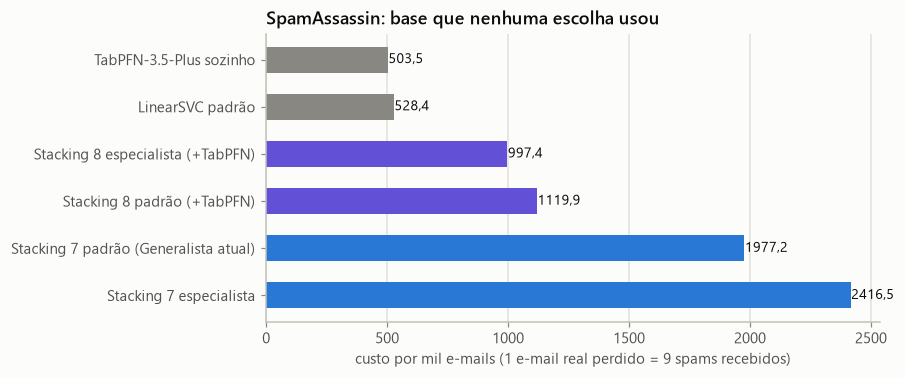

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ordem = R.sort_values("custo_por_mil", ascending=False)
cores = [graficos.CATEGORICA[6] if "8" in n else graficos.CATEGORICA[0] if "Stacking 7" in n else graficos.TINTA_MUDA for n in ordem.metodo]
ax.barh(range(len(ordem)), ordem.custo_por_mil, height=0.55, color=cores)
for i, v in enumerate(ordem.custo_por_mil):
    ax.text(v + 2, i, f"{v:.1f}".replace(".", ","), va="center", fontsize=9)
ax.set_yticks(range(len(ordem)), ordem.metodo); ax.grid(axis="y", visible=False)
ax.set_xlabel("custo por mil e-mails (1 e-mail real perdido = 9 spams recebidos)")
ax.set_title("SpamAssassin: base que nenhuma escolha usou")
graficos.mostrar(fig, "08_terceira_base")

In [8]:
saidas.gravar("08_terceira_base", {
    "terceira_base": dict(base="SpamAssassin public corpus 20030228 (easy_ham, easy_ham_2, hard_ham, spam, spam_2)",
                          n=int(len(ysa)), n_email_real=int((ysa == 0).sum()), n_spam=int((ysa == 1).sum()),
                          copias_csv_removidas=int((~mantidas).sum()), tem_tabpfn=tem_tabpfn,
                          metodos=R, decisao=decisao, controle_dentro_da_base=dentro, cobertura_vocabulario=cob),
}, fonte="scripts/08_terceira_base.py")
saidas.gravar_csv("08_terceira_base", R)
print("gravado: resultados/08_terceira_base.json")

gravado: resultados/08_terceira_base.json
